# ARES Phase 2 — Walkthrough (read-only)

This notebook **reads existing artifacts**. It does not fit, split, decode, or transform anything.

If a number below does not match `scripts/*.py` outputs, **the scripts are authoritative** — re-run them.

Run all cells: `Cell → Run All`, or from terminal: `jupyter nbconvert --to notebook --execute --inplace notebooks/Phase2_walkthrough.ipynb`

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path('..').resolve()
RES = ROOT / 'results'
def load_json(name):
    return json.loads((RES / name).read_text())

def show_png(name, caption=None):
    p = RES / name
    if p.exists():
        display(Image(filename=str(p), width=900))
        if caption: display(Markdown(f'*{caption}*'))
    else:
        print(f'missing: {p}')

## 1. Gates (content-addressed, ~1 s)

In [2]:
!python ../scripts/run_gates.py check --dataset trad_chehab --external mendeley

{
  "gate1": {
    "gate": "gate1",
    "marker_present": true,
    "manifest_present": true,
    "result_json_present": true,
    "ok": true,
    "stale_fields": [],
    "reason": null
  },
  "gate2": {
    "gate": "gate2",
    "marker_present": true,
    "manifest_present": true,
    "result_json_present": true,
    "ok": true,
    "stale_fields": [],
    "reason": null
  }
}
ALL GATES OK — safe to proceed to training.


## 2. Dataset inspection (Task 1+2)

In [3]:
ins = load_json('dataset_inspection.json')
tc = ins['trad_chehab']
print('Trad & Chehab — label map:', tc['label_to_class'])
print('Trad & Chehab — label counts:', tc['label_counts'])
print('Trad & Chehab — shape:', tc['images_shape'], tc['images_dtype'])
print()
for cls in ('benign','malicious'):
    m = ins['mendeley']['per_class'][cls]
    print(f'Mendeley {cls}: {m["n_files"]} files, corrupt={m["n_corrupt"]}')

Trad & Chehab — label map: {'0': 'benign', '1': 'malicious'}
Trad & Chehab — label counts: {'0': 5005, '1': 4982}
Trad & Chehab — shape: [9987, 69, 69] int16

Mendeley benign: 500 files, corrupt=0
Mendeley malicious: 500 files, corrupt=0


## 3. Gate 2 — full-dataset decode audit

In [4]:
g2 = load_json('full_decode_audit.json')
for slot in ('primary','external'):
    r = g2[slot]
    print(f'{slot}: {r["dataset"]}  decode_rate={r["decode_rate"]}  gate_pass={r["gate_pass"]}')
    print('  per_class_category:', r['per_class_category'])

primary: Trad & Chehab  decode_rate={'benign': 0.99, 'malicious': 0.9829}  gate_pass=True
  per_class_category: {'benign__url': 4912, 'malicious__url': 4510, 'malicious__plain_text': 387, 'benign__undecodable': 50, 'malicious__undecodable': 85, 'benign__plain_text': 43}
external: Mendeley  decode_rate={'benign': 0.998, 'malicious': 0.986}  gate_pass=True
  per_class_category: {'benign__url': 499, 'benign__undecodable': 1, 'malicious__url': 491, 'malicious__undecodable': 7, 'malicious__plain_text': 2}


## 4. Feature summary + exclusions (Task 3)

In [5]:
fs = load_json('feature_summary.json')
print('primary n_rows:', fs['primary']['n_url_features_rows'],
      ' n_excluded:', fs['primary']['n_excluded'])
print('constant features:', fs['primary']['feature_summary']['constant_features'])
print('high-corr pairs:', fs['primary']['feature_summary']['high_correlation_pairs_r_ge_0_95'])

primary n_rows: 9422  n_excluded: 565
constant features: ['has_https', 'has_ip', 'has_userinfo', 'embedded_url_in_query']
high-corr pairs: []


## 5. Split (Task 4)

In [6]:
sp = load_json('dataset_split_report.json')
rows = []
for name in ('train','val','test'):
    s = sp['primary'][f'{name}_stats']
    rows.append({'split': name, **s})
pd.DataFrame(rows)

,split,n_rows,n_benign,n_malicious,n_domains,n_empty_domain,n_unique_sample_ids
0,train,6658,3484,3174,4189,0,6658
1,val,1425,792,633,898,0,1425
2,test,1339,636,703,898,0,1339


## 6. PCA — scree + loadings (Task 5)

kept: 20  k = 13  cumulative = 0.9586
dropped: ['has_https', 'has_ip', 'has_userinfo', 'embedded_url_in_query']


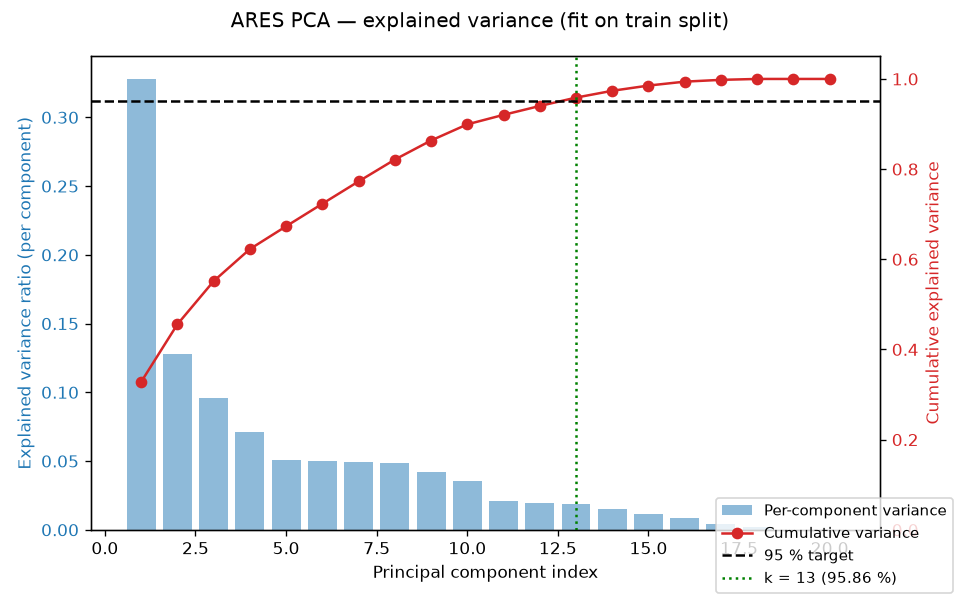

*Scree + cumulative variance*

In [7]:
pca = load_json('pca_report.json')
print('kept:', pca['n_features_kept'], ' k =', pca['n_components_selected'],
      ' cumulative =', round(pca['cumulative_explained_variance_selected'], 4))
print('dropped:', pca['features']['dropped'])
show_png('pca_explained_variance.png', 'Scree + cumulative variance')

## 7. Model comparison (Task 6, validation only)

In [8]:
mc = load_json('model_comparison.json')
rows = []
for name, m in sorted(mc['metrics'].items()):
    if 'error' in m:
        rows.append({'model': name, 'error': m['error']})
        continue
    rows.append({'model': name, 'kind': m['feature_kind'], 'family': m['family'],
                 'accuracy': m['accuracy'], 'precision': m['precision'],
                 'recall': m['recall'], 'f1': m['f1'],
                 'roc_auc': m['roc_auc'], 'pr_auc': m['pr_auc'],
                 'brier': m['brier'], 'fit_seconds': m['fit_seconds']})
df_mc = pd.DataFrame(rows).sort_values('f1', ascending=False)
print('test_set_used:', mc['test_set_used'])
df_mc

test_set_used: False


,model,kind,family,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,fit_seconds
7,raw_xgb,raw,xgb,0.881404,0.874194,0.856240,0.865124,0.949427,0.950659,0.088034,0.79
6,raw_rf,raw,rf,0.880702,0.875203,0.853081,0.864000,0.948605,0.949089,0.085741,2.20
4,raw_dt,raw,dt,0.868070,0.877759,0.816746,0.846154,0.893124,0.868799,0.113486,0.04
3,pca_xgb,pca,xgb,0.861754,0.858553,0.824645,0.841257,0.926117,0.928657,0.100961,1.00
2,pca_rf,pca,rf,0.860351,0.866554,0.810427,0.837551,0.930251,0.930307,0.099661,4.59
5,raw_lr,raw,lr,0.849825,0.866900,0.781991,0.822259,0.911862,0.914634,0.113125,0.47
0,pca_dt,pca,dt,0.819649,0.799363,0.793049,0.796193,0.876894,0.865750,0.136981,0.13
1,pca_lr,pca,lr,0.820351,0.885481,0.684044,0.771836,0.857569,0.877926,0.133892,0.07


Selected model: raw_xgb
feature_kind: raw
selection_rule: {'primary': 'mean(F1, ROC-AUC) on validation', 'tiebreak_1': 'higher validation precision', 'tiebreak_2': 'lower validation Brier', 'tiebreak_3': 'alphabetical model_name (deterministic)'}


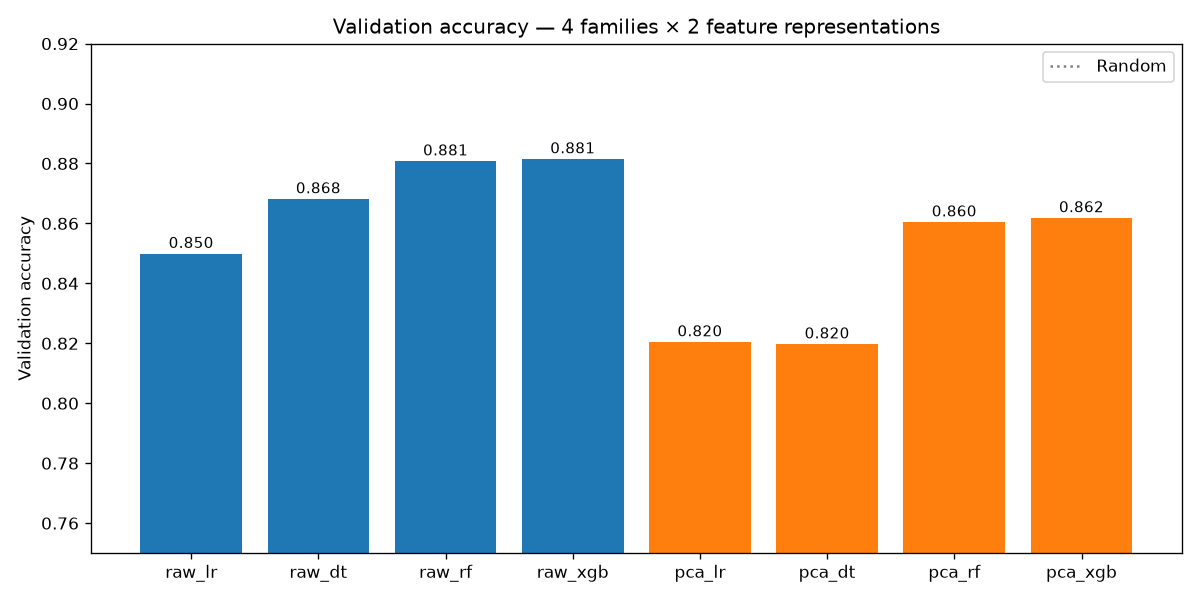

*Validation accuracy — all 8 models*

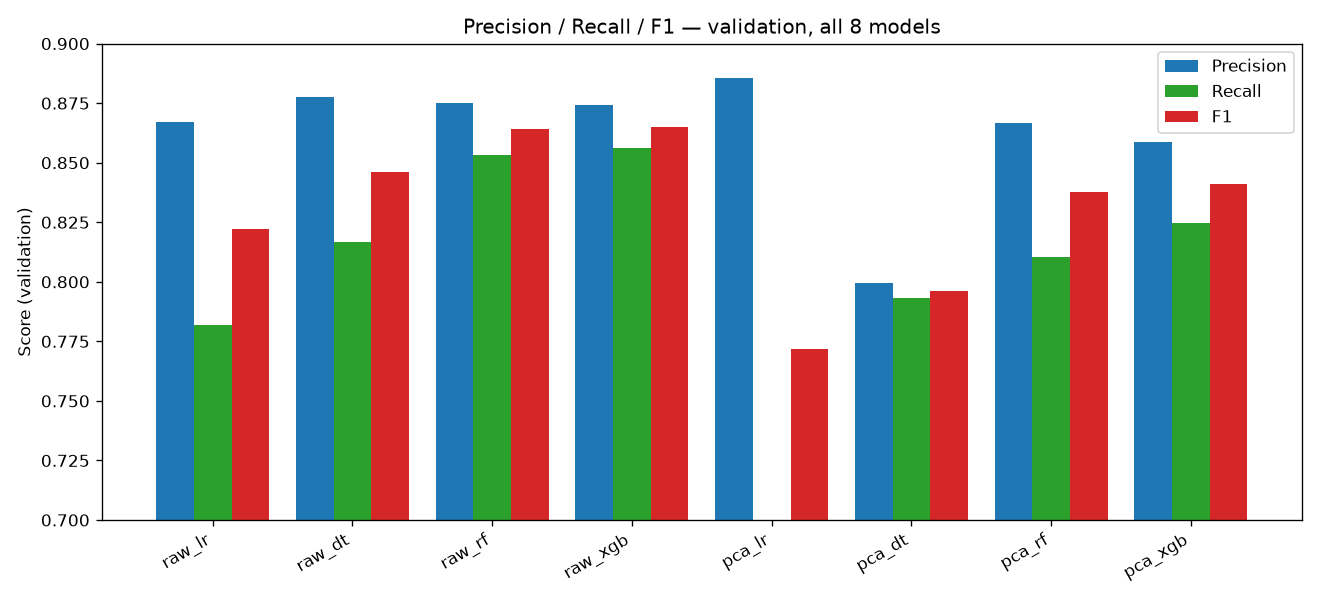

*Precision / Recall / F1 — validation*

In [9]:
ms = load_json('model_selection.json')
print('Selected model:', ms['selected_model']['model_name'])
print('feature_kind:', ms['selected_model']['feature_kind'])
print('selection_rule:', ms['selection_rule'])
show_png('model_accuracy_comparison.png', 'Validation accuracy — all 8 models')
show_png('model_precision_recall_comparison.png', 'Precision / Recall / F1 — validation')

## 8. Final evaluation (Task 7 — test + external, frozen model)

selected: raw_xgb

[test] n=1339
  accuracy  : 0.8910
  precision : 0.9078
  recall    : 0.8819
  f1        : 0.8947
  roc_auc   : 0.9490
  pr_auc    : 0.9641
  brier     : 0.0841
  confusion: [[573, 63], [83, 620]]

[external] n=990
  accuracy  : 0.4273
  precision : 0.4554
  recall    : 0.7902
  f1        : 0.5778
  roc_auc   : 0.5262
  pr_auc    : 0.6225
  brier     : 0.4965
  confusion: [[35, 464], [103, 388]]

deltas external - test: {'accuracy': -0.4637, 'f1': -0.3169, 'roc_auc': -0.4228, 'pr_auc': -0.3416, 'brier': 0.4124}


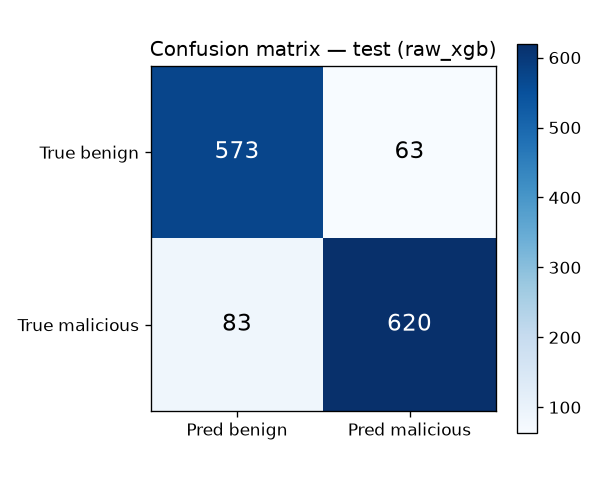

*Test confusion matrix*

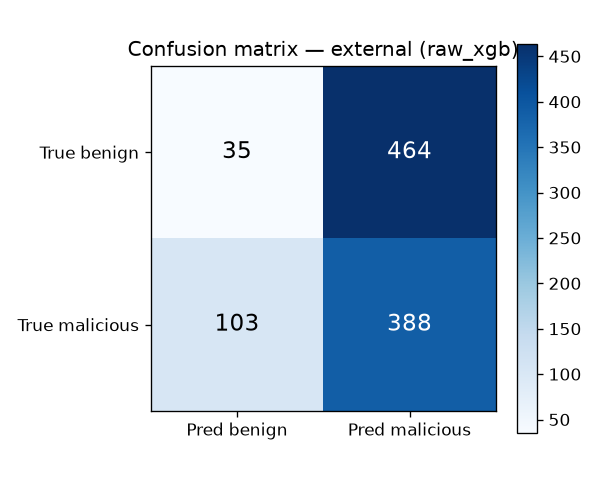

*External (Mendeley) confusion matrix*

In [10]:
try:
    fm = load_json('final_metrics.json')
    print('selected:', fm['selected_model'])
    for split in ('test','external'):
        r = fm[split]
        print(f'\n[{split}] n={r["n"]}')
        for k in ('accuracy','precision','recall','f1','roc_auc','pr_auc','brier'):
            print(f'  {k:10s}: {r[k]:.4f}')
        print('  confusion:', r['confusion_matrix'])
    print('\ndeltas external - test:', fm['deltas_external_minus_test'])
    show_png('confusion_matrices/confusion_test.png', 'Test confusion matrix')
    show_png('confusion_matrices/confusion_external.png', 'External (Mendeley) confusion matrix')
except FileNotFoundError:
    print('final_metrics.json not yet written — run scripts/evaluate_models.py first.')

## 9. Threshold sweep (input to Task 8)

In [11]:
try:
    sw = load_json('threshold_sweep.json')
    df_sw = pd.DataFrame(sw['thresholds'])
    print('n_benign:', sw['n_benign'], ' n_malicious:', sw['n_malicious'])
    df_sw.iloc[::5]  # every 5th threshold for brevity
except FileNotFoundError:
    print('threshold_sweep.json not yet written.')

n_benign: 636  n_malicious: 703


## End
If a number looks wrong, inspect the corresponding `scripts/*.py` and `results/*.json`.
The notebook cannot be out of sync with the pipeline, because it only reads the pipeline's outputs.